# Demo 4 · методи disparity на реальних парах

До слайдів **«Алгоритми обчислення disparity»**, **«Де стереозір „ламається“»**, **«Епіполюси на нескінченності»** і **«Ректифікація на практиці»**.

Тут — **реальні** стереопари Middlebury 2014 з **істинною** disparity, знятою структурованим світлом. Отже, видно не лише де алгоритм мовчить, а й де він **упевнено помиляється**, і все це на справжніх фото зі справжнім шумом, відблисками й перепадами освітлення.

Шість методів від найпростішого до нейромережі, кожен наступний лікує конкретну хворобу попереднього:

| Метод | Що додає | Слабке місце |
|---|---|---|
| **SAD · WTA** | вікно, сума різниць яскравості, мінімум | ламається від іншої експозиції |
| **Census · WTA** | порівнює не яскравість, а порядок сусідів | ніколи не мовчить |
| **StereoBM** | префільтр, перевірки текстури й унікальності | дірки на слабкій текстурі |
| **StereoSGBM** | штраф за стрибки disparity вздовж 5–8 напрямків | вигадує глибину там, де мав би мовчати |
| **SGBM + L–R** | перевірка ліва ↔ права | менша щільність |
| **RAFT** | нейромережа, пошук у 2D | секунди на CPU, заповнює все |

Сцени підібрано під пункти слайдів: повторювані труби, полиці без текстури, тонкі гілки, інша експозиція правого кадру, реальна проти ідеальної ректифікації.

> У ноутбуці лишились тільки підрахунки; віджети живуть у `panels.py` поруч.

## Дані

Потрібен MiddEval3 у чверті роздільності (≈45 МБ, ~740×500). Якщо його ще немає, з кореня репозиторію:

```
python tools/fetch_middlebury.py          # MiddEval3, чверть роздільності
python tools/fetch_middlebury.py --full   # + Motorcycle-perfect у повній роздільності
```

Повна `Motorcycle-perfect` необов'язкова. Лише в ній для **тієї самої** сцени є правий кадр з іншою **експозицією** (`im1E`) та іншим **освітленням** (`im1L`). Ноутбук зменшує її вчетверо: за розміром вона не відрізняється від решти, а три варіанти правого кадру можна порівняти між собою.

In [17]:
import hashlib
import re
import time
from functools import lru_cache

import cv2
import numpy as np
import torch

from panels import REPO_ROOT

DATA_DIR = REPO_ROOT / "artifacts" / "middlebury"
QUARTER_DIR = DATA_DIR / "MiddEval3" / "trainingQ"   # MiddEval3, чверть роздільності
FULL_MOTORCYCLE = DATA_DIR / "Motorcycle-perfect"    # необов'язково: повна роздільність з im1E / im1L
FULL_SCALE = 4                                        # повну зменшуємо до розміру решти сцен
CACHE_DIR = DATA_DIR / "cache"                        # результати RAFT: на CPU це ~8 с на пару
WEIGHTS_DIR = REPO_ROOT / "artifacts" / "models" / "torch"

BAD_PX = 2.0     # похибка, після якої піксель хибний; у рейтингу Middlebury це «bad 2.0»

### Каталог сцен

У MiddEval3 варіанти однієї сцени лежать окремими теками з однаковим лівим кадром: `MotorcycleE` — та сама сцена, але правий кадр знято з іншою експозицією, `PianoL` — з іншим освітленням, `PlaytableP` — з ідеальною ректифікацією замість реальної. Об'єднуємо їх у «сцену» з кількома варіантами правого кадру.

In [18]:
SCENES = {   # сцена → {варіант правого кадру: джерело}
    "Motorcycle": {"той самий кадр": "Q/Motorcycle", "інша експозиція": "Q/MotorcycleE"},
    "Pipes": {"—": "Q/Pipes"},
    "Shelves": {"—": "Q/Shelves"},
    "Jadeplant": {"—": "Q/Jadeplant"},
    "Piano": {"той самий кадр": "Q/Piano", "інше освітлення": "Q/PianoL"},
    "Playtable": {"ідеальна ректифікація": "Q/PlaytableP", "реальна ректифікація": "Q/Playtable"},
    "Adirondack": {"—": "Q/Adirondack"},
    "Vintage": {"—": "Q/Vintage"},
}
if (FULL_MOTORCYCLE / "disp0.pfm").exists():
    SCENES["Motorcycle"] = {"той самий кадр": "full/im1.png", "інша експозиція": "full/im1E.png",
                            "інше освітлення": "full/im1L.png"}

ABOUT = {
    "Motorcycle": "Багато текстури й дрібних деталей — базова сцена. Варіанти правого кадру: "
                  "інша експозиція та інше освітлення. Слайд «Алгоритми».",
    "Pipes": "Ряди однакових труб — повторюваний патерн: кілька однаково хороших відповідностей.",
    "Shelves": "Великі однотонні полиці й стіна — слабка текстура: зіставляти нема за чим.",
    "Jadeplant": "Тонкі гілки на тлі далекої стіни: великий діапазон disparity і багато перекриттів.",
    "Piano": "Варіант з іншим освітленням правого кадру: відблиски й тіні зміщуються.",
    "Playtable": "Реальна ректифікація має залишковий вертикальний зсув до ~0.7 px; «P» — ідеальна.",
    "Adirondack": "Крісло з рейками: повтор і тонкі щілини між ними.",
    "Vintage": "Однотонні стіни й великий діапазон пошуку — 190 px.",
}


def available(source: str) -> bool:
    kind, name = source.split("/", 1)
    return (FULL_MOTORCYCLE / name).exists() if kind == "full" else (QUARTER_DIR / name / "im0.png").exists()


SCENES = {scene: {v: s for v, s in variants.items() if available(s)} for scene, variants in SCENES.items()}
SCENES = {scene: variants for scene, variants in SCENES.items() if variants}
print(f"сцен знайдено: {len(SCENES)} — {', '.join(SCENES) or 'жодної'}")
if not SCENES:
    print("Завантаж дані: python tools/fetch_middlebury.py (з кореня репозиторію)")

сцен знайдено: 8 — Motorcycle, Pipes, Shelves, Jadeplant, Piano, Playtable, Adirondack, Vintage


## Завантаження пари й еталона

Еталон Middlebury — `disp0GT.pfm`: disparity лівого кадру у float32, рядки знизу вгору, `inf` там, де структуроване світло не дало відповіді. Маска `mask0nocc.png` ділить відомі пікселі на **видимі обом камерам** (255) і **зону перекриття** (128), яку бачить лише ліва камера — там відповідності не існує в принципі.

У повній `Motorcycle-perfect` маски немає, зате є еталон і для правого кадру (`disp1.pfm`). Перекриття знаходимо тією самою **L–R перевіркою**, що й для алгоритмів нижче: піксель видимий обом камерам, якщо права камера «бачить» його на тій самій disparity.

`calib.txt` дає `f`, базу `B` у мм і `doffs` — різницю головних точок камер `c_x1 − c_x0`. Про нього — у розділі про глибину.

In [19]:
def read_pfm(path) -> np.ndarray:
    # PFM — формат еталонів Middlebury: float32, рядки знизу вгору, inf — невідомо
    with open(path, "rb") as f:
        f.readline()
        width, height = map(int, f.readline().split())
        scale = float(f.readline())
        data = np.fromfile(f, "<f4" if scale < 0 else ">f4").reshape(height, width)
    return np.flipud(data).astype(np.float32)


def read_calib(path) -> dict:
    text = path.read_text()
    number = lambda key: float(re.search(rf"{key}=([-\d.]+)", text).group(1))
    return {"focal": float(re.search(r"cam0=\[([\d.]+)", text).group(1)),
            "baseline_mm": number("baseline"), "doffs": number("doffs"), "ndisp": number("ndisp")}


def rgb(path) -> np.ndarray:
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def visible_to_both(gt_left: np.ndarray, gt_right: np.ndarray, tolerance: float = 1.0) -> np.ndarray:
    # L–R перевірка еталона: точка x лівого кадру видна правій камері в x − d,
    # і там права disparity має збігтися з лівою. Інакше — перекриття.
    width = gt_left.shape[1]
    known = np.isfinite(gt_left)
    x_right = np.round(np.arange(width)[None, :] - np.where(known, gt_left, 0)).astype(int)
    inside = known & (x_right >= 0)
    back = np.take_along_axis(gt_right, np.clip(x_right, 0, width - 1), axis=1)
    with np.errstate(invalid="ignore"):                               # inf − inf у невідомих пікселях
        return inside & (np.abs(back - gt_left) <= tolerance)


@lru_cache(maxsize=16)
def load_scene(source: str) -> dict:
    kind, name = source.split("/", 1)
    if kind == "Q":
        folder = QUARTER_DIR / name
        left, right = rgb(folder / "im0.png"), rgb(folder / "im1.png")
        gt = read_pfm(folder / "disp0GT.pfm")
        mask = cv2.imread(str(folder / "mask0nocc.png"), cv2.IMREAD_GRAYSCALE)
        nocc, occluded = mask == 255, mask == 128
        calib, scale = read_calib(folder / "calib.txt"), 1
    else:
        folder, scale = FULL_MOTORCYCLE, FULL_SCALE
        gt_full = read_pfm(folder / "disp0.pfm")
        nocc_full = visible_to_both(gt_full, read_pfm(folder / "disp1.pfm"))
        size = (gt_full.shape[1] // scale, gt_full.shape[0] // scale)
        left = cv2.resize(rgb(folder / "im0.png"), size, interpolation=cv2.INTER_AREA)
        right = cv2.resize(rgb(folder / name), size, interpolation=cv2.INTER_AREA)
        pick = np.s_[scale // 2::scale, scale // 2::scale]           # найближчий піксель, не усереднення:
        gt = gt_full[pick][:size[1], :size[0]] / scale                # середнє по краю об'єкта — вигадана глибина
        nocc = nocc_full[pick][:size[1], :size[0]]
        occluded = np.isfinite(gt) & ~nocc
        calib = read_calib(folder / "calib.txt")

    gt = np.where(np.isfinite(gt), gt, np.nan)
    num_disp = int(np.ceil(calib["ndisp"] / scale / 16) * 16)     # OpenCV хоче кратне 16
    return {"name": source, "left": left, "right": right, "gt": gt,
            "nocc": nocc & np.isfinite(gt), "occluded": occluded & np.isfinite(gt),
            "focal": calib["focal"] / scale, "baseline_mm": calib["baseline_mm"],
            "doffs": calib["doffs"] / scale, "num_disp": num_disp}


for scene_name, variants in SCENES.items():
    s = load_scene(next(iter(variants.values())))
    print(f"{scene_name:<11} {s['left'].shape[1]}×{s['left'].shape[0]}  пошук {s['num_disp']:3d} px  "
          f"видно обом {s['nocc'].mean() * 100:3.0f}%  перекриття {s['occluded'].mean() * 100:3.0f}%  "
          f"варіанти: {', '.join(variants)}")

Motorcycle  741×497  пошук  80 px  видно обом  87%  перекриття  11%  варіанти: той самий кадр, інша експозиція
Pipes       735×485  пошук  80 px  видно обом  79%  перекриття  17%  варіанти: —
Shelves     738×497  пошук  64 px  видно обом  83%  перекриття   7%  варіанти: —
Jadeplant   659×497  пошук 160 px  видно обом  75%  перекриття  23%  варіанти: —
Piano       707×481  пошук  80 px  видно обом  86%  перекриття   8%  варіанти: той самий кадр, інше освітлення
Playtable   681×462  пошук  80 px  видно обом  86%  перекриття  11%  варіанти: ідеальна ректифікація, реальна ректифікація
Adirondack  718×496  пошук  80 px  видно обом  91%  перекриття   8%  варіанти: —
Vintage     722×480  пошук 192 px  видно обом  89%  перекриття   8%  варіанти: —


### Неідеальна ректифікація

Слайд «Епіполюси на нескінченності»: 0.3° тангажу між камерами — це ~5 px вертикального зсуву, і SGBM шукає не в тому рядку. Імітуємо це, зсунувши правий кадр угору на `dy` пікселів. Еталон не змінюється: горизонтальна disparity та сама, просто відповідник тепер лежить **не в тому рядку**, де його шукають.

In [20]:
def shift_rows(image: np.ndarray, dy: float) -> np.ndarray:
    # Зсуває кадр угору на dy px (субпіксельно): так виглядає залишок ректифікації
    if dy == 0:
        return image
    height, width = image.shape[:2]
    move = np.float32([[1, 0, 0], [0, 1, -dy]])
    return cv2.warpAffine(image, move, (width, height), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)

## Як оцінюємо

Дві цифри замість однієї:

- **щільність** — для якої частки пікселів метод узагалі дав відповідь;
- **хибні серед знайдених** — скільки з цих відповідей відхиляються від істини більш ніж на `τ` px. Саме вони небезпечні: це впевнена брехня.

Плюс метрика рейтингу Middlebury — **«дірка = помилка»**: частка пікселів, де відповідь хибна **або** її немає. Вона карає чесне мовчання так само, як брехню, — зручно для таблиці лідерів, але не для задачі, де хибна дальність дорожча за відсутню.

Усе це — на пікселях, **видимих обом камерам**. Окремо — що метод робить у **зоні перекриття**, де правильної відповіді немає: чи мовчить він там, чи переносить туди глибину сусіда.

In [21]:
def evaluate(disparity: np.ndarray, scene: dict, bad_px: float = BAD_PX) -> dict:
    found = np.isfinite(disparity)
    error = np.abs(disparity - scene["gt"])
    wrong = found & (error > bad_px)                     # NaN у порівнянні дає False
    nocc, occluded = scene["nocc"], scene["occluded"]
    n_found = (found & nocc).sum()
    n_occl_found = (found & occluded).sum()
    return {
        "density": n_found / nocc.sum(),
        "bad_found": (wrong & nocc).sum() / max(n_found, 1),
        "bad_all": ((wrong | ~found) & nocc).sum() / nocc.sum(),
        "avg_error": np.nanmean(np.where(found & nocc, error, np.nan)),
        "occl_filled": n_occl_found / max(occluded.sum(), 1),
        "occl_wrong": (wrong & occluded).sum() / n_occl_found if n_occl_found else np.nan,
    }

## 1–2 · Block matching своїми руками: SAD і Census

Будь-який локальний метод — це три кроки:

1. **вартість відповідності** для кожного пікселя й кожного кандидата `d` — наскільки вікно навколо `(x, y)` у лівому кадрі не схоже на вікно навколо `(x − d, y)` у правому;
2. **агрегація** — сума у вікні `blockSize × blockSize` (тут `boxFilter`);
3. **WTA**, winner-takes-all — для кожного пікселя беремо `d` з найменшою вартістю.

Результат — **об'єм вартості** `(numDisparities, H, W)`. На ньому ж побудована панель «крива вартості» нижче.

Дві міри несхожості:

- **SAD** — сума абсолютних різниць яскравості. Найпростіша, але варто правій камері зняти темніше — і схожі вікна стають «несхожими».
- **Census** — кожен піксель кодуємо бітовою маскою «сусід темніший за центр?» у вікні 7×7 (48 біт), а несхожість — відстань Геммінга між масками. Маска не змінюється від експозиції чи гами — лише від порядку яскравостей.

WTA **ніколи не мовчить**: мінімум є завжди, навіть на білій стіні. Тому щільність тут 100 %.

In [22]:
CENSUS_RADIUS = 3      # вікно 7×7 → 48 біт, вміщується в uint64


def census_transform(gray: np.ndarray, radius: int = CENSUS_RADIUS) -> np.ndarray:
    # Кожен піксель → бітова маска «сусід темніший за центр?»
    height, width = gray.shape
    padded = cv2.copyMakeBorder(gray, radius, radius, radius, radius, cv2.BORDER_REFLECT)
    code = np.zeros((height, width), np.uint64)
    for dy in range(-radius, radius + 1):
        for dx in range(-radius, radius + 1):
            if dy or dx:
                neighbour = padded[radius + dy:radius + dy + height, radius + dx:radius + dx + width]
                code = (code << np.uint64(1)) | (neighbour < gray).astype(np.uint64)
    return code


def cost_volume(left: np.ndarray, right: np.ndarray, num_disp: int, block: int, kind: str) -> np.ndarray:
    # Об'єм вартості (num_disp, H, W) для сірих кадрів; inf — кандидат виходить за лівий край
    height, width = left.shape
    volume = np.full((num_disp, height, width), np.inf, np.float32)
    if kind == "census":
        left_code, right_code = census_transform(left), census_transform(right)
    else:
        left_f, right_f = left.astype(np.float32), right.astype(np.float32)
    for d in range(num_disp):
        if kind == "census":
            #diff = np.bitwise_count(left_code[:, d:] ^ right_code[:, :width - d]).astype(np.float32)
            diff = np.unpackbits(
                (left_code[:, d:] ^ right_code[:, :width - d]).astype(np.uint8),
                axis=-1
            ).sum(axis=-1)
        else:
            diff = np.abs(left_f[:, d:] - right_f[:, :width - d])
        volume[d, :, d:] = cv2.boxFilter(diff, -1, (block, block), borderType=cv2.BORDER_REFLECT)
    return volume


def gray(image: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)


def wta(left, right, num_disp, block, kind) -> np.ndarray:
    return np.argmin(cost_volume(gray(left), gray(right), num_disp, block, kind), axis=0).astype(np.float32)

## 3–5 · OpenCV: StereoBM, StereoSGBM і L–R перевірка

**StereoBM** — той самий block matching, але з двома речами, яких бракує WTA вище:

- **префільтр**: горизонтальний Собель замість сирої яскравості — тому експозиція йому майже не страшна;
- **право промовчати**: `textureThreshold` відкидає вікна без текстури, `uniquenessRatio` — піксель, де другий мінімум майже такий самий, як перший.

**StereoSGBM** додає до вартості відповідності **штраф за гладкість**: `P1` — за зміну disparity на ±1 px між сусідами, `P2` — за більший стрибок. Мінімізація йде вздовж 5 (`SGBM`), 3 (`3WAY`, найшвидший) або 8 (`HH`) напрямків. Звідси чіткі краї — і звідси ж упевнена «вигадана» глибина: на білій стіні штраф гладкості просто протягує сусідню disparity.

**L–R перевірка** (left–right consistency) — найдешевший спосіб змусити алгоритм промовчати: рахуємо disparity ще й для правого кадру (дзеркально відобразивши обидва) і лишаємо лише пікселі, де ліва й права відповіді узгоджуються. Перекриття й більшість вигаданої глибини відпадають самі собою.

OpenCV повертає disparity з фіксованою комою (×16), недійсні значення — від'ємні.

In [23]:
SGBM_MODES = {"sgbm": cv2.STEREO_SGBM_MODE_SGBM, "3way": cv2.STEREO_SGBM_MODE_SGBM_3WAY,
              "hh": cv2.STEREO_SGBM_MODE_HH}


def from_fixed_point(raw: np.ndarray) -> np.ndarray:
    disparity = raw.astype(np.float32) / 16.0
    return np.where(disparity > 0, disparity, np.nan)


def stereo_bm(left, right, num_disp, block) -> np.ndarray:
    matcher = cv2.StereoBM_create(numDisparities=num_disp, blockSize=max(block, 5))
    return from_fixed_point(matcher.compute(gray(left), gray(right)))


def sgbm_disparity(left, right, num_disp, block, p1=8, p2=32, uniqueness=10, speckle=100,
                   lr_check=False, mode="3way") -> np.ndarray:
    # P1, P2 — множники при 3·blockSize², як у прикладах OpenCV для кольорових кадрів
    area = 3 * block * block
    p1_value = p1 * area
    p2_value = max(p2 * area, p1_value + 1)     # OpenCV вимагає P2 > P1

    def matcher():
        return cv2.StereoSGBM_create(minDisparity=0, numDisparities=num_disp, blockSize=block,
                                     P1=p1_value, P2=p2_value, uniquenessRatio=uniqueness,
                                     speckleWindowSize=speckle, speckleRange=2, disp12MaxDiff=-1,
                                     mode=SGBM_MODES[mode])

    disparity = from_fixed_point(matcher().compute(left, right))
    if not lr_check:
        return disparity
    # disparity правого кадру: дзеркалимо обидва кадри й міняємо їх місцями
    right_disp = np.fliplr(from_fixed_point(matcher().compute(np.fliplr(right).copy(),
                                                              np.fliplr(left).copy())))
    return lr_consistent(disparity, right_disp)


def lr_consistent(left_disp: np.ndarray, right_disp: np.ndarray, tolerance: float = 1.0) -> np.ndarray:
    # Лишаємо лише пікселі, де права disparity в точці x − d збігається з лівою
    width = left_disp.shape[1]
    x_right = np.round(np.arange(width)[None, :] - np.nan_to_num(left_disp)).astype(int)
    back = np.take_along_axis(right_disp, np.clip(x_right, 0, width - 1), axis=1)
    agree = (x_right >= 0) & (np.abs(back - left_disp) <= tolerance)
    return np.where(agree, left_disp, np.nan)

## 6 · Нейромережа: RAFT

Спеціалізовані стерео-мережі (RAFT-Stereo, CREStereo, IGEV) у стандартному `torchvision` відсутні, тож беремо їхнього прямого предка — **RAFT** для оптичного потоку, навчений на синтетиці й KITTI. На ректифікованій парі потік із лівого кадру в правий — це `(−d, 0)`: горизонтальна складова і є disparity зі знаком мінус. RAFT-Stereo — це та сама архітектура, у якій пошук обмежили рядком.

Два наслідки, які видно на панелі:

- RAFT шукає **у 2D**, тож неідеальна ректифікація його не ламає. Більше того, він **вимірює** вертикальний зсув — готова health-метрика;
- він **ніколи не мовчить**: щільність 100 %, зокрема в зоні перекриття й на слабкій текстурі. Слайд «Алгоритми»: доменний розрив — і мережа вигадує глибину.

Ваги (~20 МБ) завантажуються один раз у `artifacts/models/torch`. На CPU одна пара — ~8 с, тож результат кешуємо на диск за хешем кадрів.

In [24]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RAFT_ITERATIONS = 12
_raft = {}


def raft_model():
    if "net" not in _raft:
        torch.hub.set_dir(str(WEIGHTS_DIR))
        from torchvision.models.optical_flow import Raft_Large_Weights, raft_large
        _raft["net"] = raft_large(weights=Raft_Large_Weights.C_T_SKHT_V2).eval().to(DEVICE)
    return _raft["net"]


def raft_flow(left: np.ndarray, right: np.ndarray) -> tuple[np.ndarray, np.ndarray, float]:
    # Потік лівий → правий: (dx, dy) у px і час обчислення. Кешуємо на диск за хешем кадрів.
    key = hashlib.md5(left.tobytes() + right.tobytes() + bytes([RAFT_ITERATIONS])).hexdigest()[:16]
    path = CACHE_DIR / f"raft_{key}.npz"
    if path.exists():
        cached = np.load(path)
        return cached["dx"], cached["dy"], float(cached["seconds"])

    height, width = left.shape[:2]
    pad = ((0, -height % 8), (0, -width % 8), (0, 0))          # RAFT хоче розміри, кратні 8

    def tensor(image):
        image = np.pad(image, pad, mode="edge")
        return (torch.from_numpy(image).permute(2, 0, 1)[None].float() / 127.5 - 1).to(DEVICE)

    started = time.perf_counter()
    with torch.inference_mode():
        flow = raft_model()(tensor(left), tensor(right), num_flow_updates=RAFT_ITERATIONS)[-1][0]
    seconds = time.perf_counter() - started
    dx, dy = flow[0, :height, :width].cpu().numpy(), flow[1, :height, :width].cpu().numpy()
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path, dx=dx, dy=dy, seconds=seconds)
    return dx, dy, seconds


def raft_disparity(left, right, num_disp, block):
    dx, _, seconds = raft_flow(left, right)
    return -dx, seconds                  # час справжнього обчислення, навіть якщо взято з кешу


def raft_vertical(left, right) -> float:
    # Медіанний вертикальний зсув відповідників: на ідеальній парі ≈ 0.
    # Потік іде з лівого кадру в правий, а правий зсунуто вгору — тому знак мінус.
    return -float(np.median(raft_flow(left, right)[1]))

### Усі шість — одним словником

Кожен метод — функція `(left, right, numDisparities, blockSize) → disparity`, `NaN` там, де відповіді немає. `blockSize` для SGBM свідомо менший: агрегацію там робить штраф гладкості, а велике вікно лише розмиває краї.

In [25]:
METHODS = {
    "SAD · WTA": lambda l, r, nd, b: wta(l, r, nd, b, "sad"),
    "Census · WTA": lambda l, r, nd, b: wta(l, r, nd, b, "census"),
    "StereoBM": stereo_bm,
    "StereoSGBM": lambda l, r, nd, b: sgbm_disparity(l, r, nd, max(3, b // 2 | 1)),
    "SGBM + L–R": lambda l, r, nd, b: sgbm_disparity(l, r, nd, max(3, b // 2 | 1), lr_check=True),
    "RAFT (нейромережа)": raft_disparity,
}


def run_method(name: str, scene: dict, block: int = 9) -> np.ndarray:
    # Лише disparity: кешований RAFT повертає ще й справжній час обчислення
    value = METHODS[name](scene["left"], scene["right"], scene["num_disp"], block)
    return value[0] if isinstance(value, tuple) else value

### Звірка: одна сцена, три варіанти правого кадру

Перш ніж дивитися на панель, — таблиця чисел для Motorcycle. Перший запуск RAFT займе ~10 с на кожен варіант, далі — з кешу.

In [26]:
def compare(scene_name: str, block: int = 9, bad_px: float = BAD_PX) -> None:
    print(f"{'':<17}" + "".join(f"{name.split(' (')[0]:>15}" for name in METHODS))
    for variant, source in SCENES[scene_name].items():
        scene = load_scene(source)
        row = []
        for name in METHODS:
            s = evaluate(run_method(name, scene, block), scene, bad_px)
            row.append(f"{s['bad_all'] * 100:5.0f}% ({s['density'] * 100:3.0f}%)")
        print(f"{variant:<17}" + "".join(f"{cell:>15}" for cell in row))
    print("\nхибні, дірка = помилка (у дужках — щільність)")


compare("Motorcycle")

                       SAD · WTA   Census · WTA       StereoBM     StereoSGBM     SGBM + L–R           RAFT
той самий кадр        23% (100%)     53% (100%)     22% ( 81%)     13% ( 91%)     20% ( 82%)      7% (100%)
інша експозиція       83% (100%)     53% (100%)     24% ( 80%)     23% ( 81%)     47% ( 55%)      7% (100%)

хибні, дірка = помилка (у дужках — щільність)


## Панель · шість методів поруч

Що показати на занятті (числа — для `blockSize = 9`, `τ = 2 px`):

1. **Motorcycle, той самий кадр.** Census · WTA — 5 %, RAFT — 7 %, SGBM — 12 %, BM — 22 %. Не поспішай хвалити WTA: подивись на останні дві колонки. Він дає відповідь для **всієї** зони перекриття, і 85 % цих відповідей хибні. У SGBM серед знайденого хибних лише 3 %, а 12 % у рейтингу — здебільшого чесні дірки. Перемкни на **Disparity**: у BM рвані краї, SGBM чистий, RAFT гладкий.
2. **Інша експозиція.** SAD: 21 → 85 %, Census не помічає зміни (5 %). Census порівнює порядок яскравостей, а не яскравість, BM рятує префільтр. **Інше освітлення** складніше: тіні й відблиски зміщуються, і вже Census падає до 21 %, SGBM — до 42 %. Дві камери ніколи не мають однакової експозиції, тож сирий SAD у продукті — помилка.
3. **Shelves**, слабка текстура. BM чесно мовчить (щільність 56 %, хибних серед знайдених 12 %). SGBM заповнює полиці (80 %), і хибних серед знайденого більше — 18 %. Метод, що виглядає гірше на картинці, може бути безпечнішим.
4. **Pipes**, повторюваний патерн. Помаранчеві плями на трубах там, де WTA обрав сусідню трубу. SAD — 25 %, Census — 12 %, RAFT тут не кращий за SGBM.
5. **Jadeplant**, перекриття: 23 % кадру видно лише лівій камері. WTA і RAFT відповідають для 100 % цієї зони (WTA помиляється в 92 % з них, RAFT — у 59 %). L–R перевірка лишає відповідь лише для 11 %.
6. **Вертикальний зсув** на Motorcycle: 1 px — SGBM 12 → 18 %, Census 5 → 29 %; 2 px — SGBM 36 %, Census 67 %. RAFT тримає 7 % і під таблицею **вимірює** зсув: +1.04, +2.04 px. **Playtable · реальна ректифікація** без жодного зсуву: RAFT бачить −0.27 px, а в `calib.txt` сцени записано `dyavg=0.24`. Це справжній залишок калібрування, і його вистачає, щоб Census погіршився з 18 до 32 %.
7. **blockSize.** Більше вікно — менше шуму на площинах, але товщі краї й зникають тонкі гілки Jadeplant.

RAFT на CPU рахує 3–8 с на нову пару, перший запуск — ще й з завантаженням ваг. Далі — з кешу.

In [27]:
from panels import launch_disparity_methods

launch_disparity_methods(SCENES, ABOUT, load_scene, METHODS, evaluate, shift_rows,
                         vertical_probe=raft_vertical)

## Панель · крива вартості в одному пікселі

Щоб зрозуміти **чому** метод помиляється, дивимось на вартість відповідності для одного пікселя лівого кадру: 1D-криву вздовж його рядка в правому кадрі. WTA бере її мінімум — і все.

Точки підбираються автоматично для кожної сцени:

- **текстура** — різкий єдиний мінімум, будь-яке вікно знаходить правильну відповідь;
- **слабка текстура** — крива пласка, мінімум визначає шум;
- **SAD помиляється попри текстуру** — на повторюваному патерні мінімумів кілька, а при іншій експозиції мінімум SAD просто зсувається;
- **перекриття** — правильного мінімуму немає взагалі, алгоритм однаково щось обере.

Три розміри вікна показують компроміс `blockSize`: мале вікно — шумна крива з хибними мінімумами, велике — гладка, але «змазує» краї об'єктів.

In [28]:
def pick_points(scene: dict, seed: int = 0) -> dict:
    # Характерні пікселі: текстура, слабка текстура, неоднозначний мінімум, перекриття
    rng = np.random.default_rng(seed)
    left = gray(scene["left"]).astype(np.float32)
    height, width = left.shape
    local_std = np.sqrt(np.maximum(cv2.blur(left ** 2, (11, 11)) - cv2.blur(left, (11, 11)) ** 2, 0))
    guess = wta(scene["left"], scene["right"], scene["num_disp"], 11, "sad")
    error = np.abs(guess - scene["gt"])

    inside = np.zeros((height, width), bool)
    inside[20:height - 20, scene["num_disp"] + 20:width - 20] = True
    textured = local_std > np.nanpercentile(local_std[scene["nocc"]], 70)
    flat = local_std < np.nanpercentile(local_std[scene["nocc"]], 8)
    candidates = {
        "текстура: різкий мінімум": inside & scene["nocc"] & textured & (error <= 0.5),
        "слабка текстура: пласка крива": inside & scene["nocc"] & flat,
        "SAD помиляється попри текстуру": inside & scene["nocc"] & textured & (error > 8),
        "перекриття: відповідності немає": inside & scene["occluded"],
    }
    points = {}
    for label, mask in candidates.items():
        ys, xs = np.nonzero(mask)
        if len(xs):
            i = rng.integers(len(xs))
            points[label] = (int(xs[i]), int(ys[i]))
    return points


print(pick_points(load_scene(SCENES["Pipes"]["—"])) if "Pipes" in SCENES else "")

{'текстура: різкий мінімум': (532, 383), 'слабка текстура: пласка крива': (565, 259), 'SAD помиляється попри текстуру': (254, 290), 'перекриття: відповідності немає': (279, 231)}


Що показати:

- **Pipes** · «SAD помиляється попри текстуру»: у кривої SAD дві майже однакові ями (44 і 53 px), і WTA обирає не ту. У Census яма одна, на істині;
- **Pipes** · «перекриття»: у кривої немає правильного мінімуму, але WTA однаково щось обирає, і кожне вікно — своє;
- **Shelves** · «слабка текстура»: крива майже горизонтальна, мінімум гуляє залежно від розміру вікна;
- **Motorcycle · інша експозиція** · «SAD помиляється попри текстуру»: текстура є, але різниця яскравості спотворює всю криву SAD, і її мінімум тікає далеко від істини. У Census яма лишається рівно на істині.

Будь-яку точку можна задати вручну слайдерами `x`, `y`.

In [29]:
from panels import launch_cost_curve

launch_cost_curve(SCENES, load_scene, cost_volume, pick_points)

## Панель · штрафи гладкості SGBM

SGBM мінімізує енергію `E(D) = Σ C(p, d_p) + Σ P1·[|d_p − d_q| = 1] + Σ P2·[|d_p − d_q| > 1]` — вартість відповідності плюс штрафи за зміну disparity між сусідами.

- **P1 → 0, P2 → 0** — штрафів немає, SGBM вироджується у звичайний WTA: шум і плями;
- **великий P2** — стрибки дорогі: площини гладкі, але краї об'єктів «розпливаються», тонкі деталі зникають. Профіль рядка внизу показує це найкраще;
- **uniquenessRatio**, **фільтр плям** і **L–R перевірка** — три способи промовчати замість вигадувати. Кожен знижує щільність і «хибні серед знайдених» — і дає вищу «дірку = помилку». Яку з метрик оптимізувати, залежить від задачі, а не від рейтингу.

In [30]:
from panels import launch_sgbm_tuning

launch_sgbm_tuning(SCENES, load_scene, sgbm_disparity, evaluate)

## Від disparity до міліметрів

Для Middlebury формула зі слайда має додатковий доданок: **Z = f·B / (d + doffs)**, де `doffs = c_x1 − c_x0` — різниця головних точок камер. Це рівно той випадок зі слайда «Ректифікація на практиці»: без `CALIB_ZERO_DISPARITY` головні точки розходяться, і наївна `Z = f·B/d` бреше. Тут — на реальній калібровці, а не на прикладі.

Посередині — той самий закон **ΔZ = Z²·Δd / (f·B)**, що на слайді, але вже на реальних похибках методів: SGBM лягає на криву з `Δd ≈ 0.25 px`, тобто субпіксельна точність у нього справжня. Праворуч — що буде, якщо забути `doffs`: disparity систематично занижена на 31 px, і дальність завищується на 60–280 %. Жодного винятку, лише правдоподібні, але хибні числа.

f = 999 px, B = 193 мм, doffs = 32.8 px, глибина сцени 2.0–4.6 м


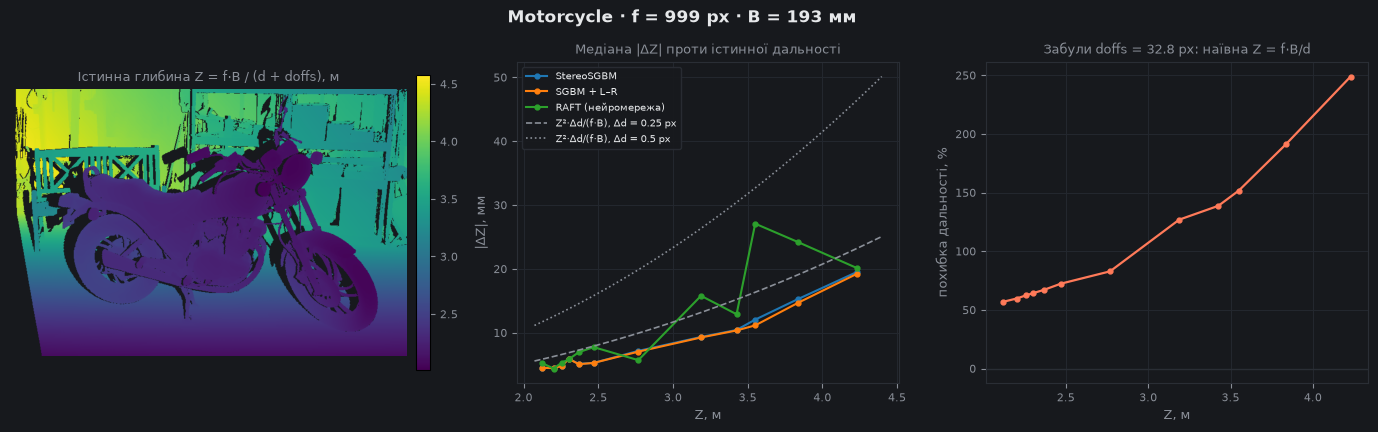

In [31]:
from panels import show_depth_law


def depth_mm(disparity: np.ndarray, scene: dict, with_doffs: bool = True) -> np.ndarray:
    # Z = f·B / (d + doffs). Без doffs — наївна формула, яка ігнорує різницю головних точок.
    offset = scene["doffs"] if with_doffs else 0.0
    with np.errstate(divide="ignore", invalid="ignore"):
        return scene["focal"] * scene["baseline_mm"] / (disparity + offset)


def depth_error_theory(z_mm: np.ndarray, scene: dict, disparity_error_px: float) -> np.ndarray:
    # ΔZ = Z²·Δd / (f·B)
    return z_mm ** 2 * disparity_error_px / (scene["focal"] * scene["baseline_mm"])


scene = load_scene(SCENES["Motorcycle"]["той самий кадр"])
disparities = {name: run_method(name, scene) for name in ("StereoSGBM", "SGBM + L–R", "RAFT (нейромережа)")}

z = depth_mm(scene["gt"], scene)[scene["nocc"]]
print(f"f = {scene['focal']:.0f} px, B = {scene['baseline_mm']:.0f} мм, doffs = {scene['doffs']:.1f} px, "
      f"глибина сцени {np.nanmin(z) / 1000:.1f}–{np.nanmax(z) / 1000:.1f} м")
show_depth_law(scene, disparities, depth_mm, depth_error_theory, title="Motorcycle")

## Що з цього взяти

- **Рейтинг ≠ ваша задача.** «Дірка = помилка» ставить WTA і RAFT вище за SGBM + L–R. Але для системи, яка приймає рішення за дальністю, небезпечніші «хибні серед знайдених», і там порядок часто протилежний: на Vintage у SGBM 18 % хибних серед знайденого, у SGBM + L–R — 6 %.
- **Мовчання — це фіча.** `uniquenessRatio`, фільтр плям і L–R перевірка майже нічого не коштують і прибирають більшість упевненої брехні, особливо в зоні перекриття.
- **Фотометрія важливіша, ніж здається.** Дві камери ніколи не мають однакової експозиції. Census чи префільтр потрібні обов'язково, сирий SAD — ні.
- **Нейромережа заповнює все.** На Middlebury RAFT — найкращий майже скрізь: це сцени в приміщенні, близькі до його навчальних даних. Але він ніколи не каже «не знаю» — ні в перекритті, ні на слабкій текстурі. На небі, в LWIR чи в аерозйомці це вигадана глибина без жодного сигналу, що вона вигадана (слайд «Рейтинг KITTI ≠ ваша задача»). І він у сотні разів повільніший за SGBM.
- **Ректифікація — не формальність.** Один піксель вертикального зсуву помітно псує класичні методи. RAFT його не лише витримує, а й вимірює, а отже, це дешева онлайн-перевірка калібрування.